<a href="https://colab.research.google.com/github/Business-Intelligence-Book/business-intelligence-book.github.io/blob/main/labs/06-regression-1/walkthrough/walkthrough.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1 style="color:#2F5597"><span style="background:#2F5597;color:#fff;padding:2px 10px;border-radius:3px">Lab 06</span>&nbsp; Regression I</h1>

<p style="color:#595959"><b style="color:#C55A11">Walkthrough</b> · Linear regression · <i>Business Intelligence and Analytics</i> · Chapter 7</p>

<div style="background:#FFF2CC;border-radius:10px;padding:14px 20px;margin:12px 0;color:#222">
<p style="margin:0 0 6px 0"><b style="color:#C55A11">💡 What you will learn this week</b></p>
<ul style="margin:0">
<li>How to split a dataset into a training set and a test set</li>
<li>How to scale features</li>
<li>How to fit a linear regression with scikit-learn</li>
<li>How to evaluate a model with R², MAE and MSE</li>
<li>How to use several features to predict one target</li>
</ul>
</div>

Run the cells from top to bottom. Text cells explain each step; code cells show how to do it in Python.

---

Regression relates input variables to an output variable, either to predict the output for new inputs or to understand the effect of the inputs on the output.

In prediction, we want to predict the output for a new input vector.

In interpretation, we want to understand the effect of the inputs on the output.

For both goals, we need a function that approximates the output "well enough" given the inputs:

$$y_n =f(\boldsymbol{x_{n}})$$

In Python, the **scikit-learn** library (imported as `sklearn`) offers regression and many other machine learning and statistical tools.

This walkthrough shows how to use it for regression.

<div style="background:#E8EEF7;border-radius:10px;padding:14px 20px;margin:12px 0;color:#222">
<p style="margin:0 0 6px 0"><b style="color:#2F5597">⭐ Fun fact: Why is it called regression?</b></p>
In the 1880s Francis Galton compared the heights of parents and their adult children. He found that very tall parents tend to have children who are tall, but less so than themselves, and that the same holds for short parents. He called this "regression towards mediocrity", and the name stuck to the method he used to describe it.
</div>

In [1]:
import matplotlib.pylab as plt
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error
from sklearn.preprocessing import MinMaxScaler
pd.set_option('display.max_columns', None)
# %matplotlib inline

## 1. Load the dataset


We have imported `LinearRegression` from scikit-learn. In this section, we go through the basics of the linear model with a weather dataset. In the exercises, you will then run your own linear regression.

In [2]:
# Load the dataset
url = "https://raw.githubusercontent.com/Business-Intelligence-Book/business-intelligence-book.github.io/main/labs/data/weather.csv"
weather = pd.read_csv(url).drop_duplicates().dropna()

# Display a sample of the data
display(weather.head())

# Print the data types
print(weather.dtypes)
print("Data matrix shape: ", weather.shape)

# Display the columns names
print("Columns names: ", weather.columns)

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RISK_MM,RainTomorrow
0,2007-11-01,Canberra,8.0,24.3,0.0,3.4,6.3,NW,30.0,SW,NW,6.0,20,68,29,1019.7,1015.0,7,7,14.4,23.6,No,3.6,Yes
1,2007-11-02,Canberra,14.0,26.9,3.6,4.4,9.7,ENE,39.0,E,W,4.0,17,80,36,1012.4,1008.4,5,3,17.5,25.7,Yes,3.6,Yes
2,2007-11-03,Canberra,13.7,23.4,3.6,5.8,3.3,NW,85.0,N,NNE,6.0,6,82,69,1009.5,1007.2,8,7,15.4,20.2,Yes,39.8,Yes
3,2007-11-04,Canberra,13.3,15.5,39.8,7.2,9.1,NW,54.0,WNW,W,30.0,24,62,56,1005.5,1007.0,2,7,13.5,14.1,Yes,2.8,Yes
4,2007-11-05,Canberra,7.6,16.1,2.8,5.6,10.6,SSE,50.0,SSE,ESE,20.0,28,68,49,1018.3,1018.5,7,7,11.1,15.4,Yes,0.0,No


Date                 str
Location             str
MinTemp          float64
MaxTemp          float64
Rainfall         float64
Evaporation      float64
Sunshine         float64
WindGustDir          str
WindGustSpeed    float64
WindDir9am           str
WindDir3pm           str
WindSpeed9am     float64
WindSpeed3pm       int64
Humidity9am        int64
Humidity3pm        int64
Pressure9am      float64
Pressure3pm      float64
Cloud9am           int64
Cloud3pm           int64
Temp9am          float64
Temp3pm          float64
RainToday            str
RISK_MM          float64
RainTomorrow         str
dtype: object
Data matrix shape:  (328, 24)
Columns names:  Index(['Date', 'Location', 'MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation',
       'Sunshine', 'WindGustDir', 'WindGustSpeed', 'WindDir9am', 'WindDir3pm',
       'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm',
       'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am',
       'Temp3pm', 'RainToday', 'RISK_MM', 'R

In [3]:
# Display correlation of the features for numeric_only features
display(weather.corr(numeric_only=True))
display(weather.corrwith(weather['Temp3pm'], numeric_only=True))

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RISK_MM
MinTemp,1.000000,0.745911,0.197339,0.634720,0.007730,0.190596,0.058319,-0.106321,-0.160781,-0.013897,-0.502352,-0.503255,0.211640,0.125914,0.910805,0.716051,0.251519
MaxTemp,0.745911,1.000000,-0.077263,0.673162,0.444863,0.070911,-0.296485,-0.219886,-0.325106,-0.520412,-0.268054,-0.367040,-0.187416,-0.144976,0.869609,0.988925,0.058638
Rainfall,0.197339,-0.077263,1.000000,-0.011767,-0.158062,0.099442,0.238705,0.058151,0.146321,0.287244,-0.348731,-0.263710,0.172610,0.134894,0.071893,-0.089740,0.101909
Evaporation,0.634720,0.673162,-0.011767,1.000000,0.310124,0.258050,0.006259,0.019594,-0.492218,-0.374532,-0.363936,-0.380702,-0.114261,-0.111387,0.688749,0.655896,0.099727
Sunshine,0.007730,0.444863,-0.158062,0.310124,1.000000,0.084768,-0.103841,0.046140,-0.501596,-0.760267,0.025630,-0.024120,-0.697603,-0.657198,0.199659,0.463721,-0.357231
WindGustSpeed,0.190596,0.070911,0.099442,0.258050,0.084768,1.000000,0.540717,0.687071,-0.338276,-0.043254,-0.524737,-0.510826,-0.018216,0.042849,0.229164,0.036039,0.269151
WindSpeed9am,0.058319,-0.296485,0.238705,0.006259,-0.103841,0.540717,1.000000,0.495946,-0.222337,0.202122,-0.344290,-0.233682,0.117625,-0.012990,-0.017843,-0.315906,0.053529
WindSpeed3pm,-0.106321,-0.219886,0.058151,0.019594,0.046140,0.687071,0.495946,1.000000,-0.260960,0.015860,-0.344889,-0.318008,-0.033882,0.011625,-0.057454,-0.239119,0.012931
Humidity9am,-0.160781,-0.325106,0.146321,-0.492218,-0.501596,-0.338276,-0.222337,-0.260960,1.000000,0.526695,0.102250,0.109549,0.417496,0.289618,-0.395647,-0.321299,0.157148
Humidity3pm,-0.013897,-0.520412,0.287244,-0.374532,-0.760267,-0.043254,0.202122,0.015860,0.526695,1.000000,-0.136289,-0.047607,0.565174,0.530715,-0.230820,-0.569348,0.323494


MinTemp          0.716051
MaxTemp          0.988925
Rainfall        -0.089740
Evaporation      0.655896
Sunshine         0.463721
WindGustSpeed    0.036039
WindSpeed9am    -0.315906
WindSpeed3pm    -0.239119
Humidity9am     -0.321299
Humidity3pm     -0.569348
Pressure9am     -0.229817
Pressure3pm     -0.332099
Cloud9am        -0.213509
Cloud3pm        -0.181667
Temp9am          0.843509
Temp3pm          1.000000
RISK_MM          0.028888
dtype: float64

**Note:** the goal is to predict the temperature from other features (such as humidity or pressure). With one input feature, this is a univariate linear regression; with several, a multivariate linear regression. For simplicity, we only use the values measured at **3pm**.

With one feature, a linear regression has this form: $$ y_i = w_0 + w_1 x_i + \epsilon_i$$

where
- $y_i$ is the target variable (dependent variable) for observation i,
- $x_i$ is the feature (independent variable),
- $w_0$ (intercept) and $w_1$ (coefficient) are the parameters of the model, also called weights,
- $\epsilon_i$ is the error term, the noise or variability that the model does not capture.

`LinearRegression` computes the best values of $w_0$ and $w_1$.

With several features, we write the model in matrix form:
$$\mathbf{y} = X\mathbf{w} + \mathbf{\epsilon}$$

where
- $X$ is the feature matrix,
- $\mathbf{w}$ is the vector of coefficients, and
- $\mathbf{y}$ is the vector of target values.

For now we focus on a simple linear regression with **one feature**. Can we use the humidity to predict the temperature? Let's separate the input feature from the target output.

In [4]:
X = weather[['Humidity3pm']]
y = weather[['Temp3pm']]

## 2. Splitting the dataset
scikit-learn provides a function to split a dataset into a training set and a test set. The **training set** is used to learn the best weights, by fitting the model to input-output pairs. The **test set** is used to evaluate the model on data it has not seen.

Testing on separate data shows whether the model generalizes well to new inputs.

Here the test set is 20% of the original dataset.

In [5]:
# Split the data into training/testing sets
# Split the targets into training/testing sets
# Fix the random seed to zero to ensure reproducibility
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0, shuffle=True)

**Note:** in general, you should scale the data right after splitting the dataset. Scaling puts all features on a comparable range, which matters for many models. We skip this step for now.

scikit-learn offers `MinMaxScaler` for this. It rescales each feature individually so that its values on the training set lie in a given range, by default between zero and one.

Always fit the scaler on the training data, and then use the fitted scaler to transform the test data. Here is an example:

```python
from sklearn.preprocessing import MinMaxScaler
# Define the scaler
scaler = MinMaxScaler()

# Fit the scaler
scaler.fit(X_train)
# Transform the train and the test set
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

# The first two steps can be merged into one (only for the train set)
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
```

## 3. Create and fit the model

To predict the target variable we use a simple linear regression. The model is imported as follows (already done at the top of the notebook):

```python
from sklearn.linear_model import LinearRegression
```

**Note:**
- We create a new `LinearRegression` model.
- The `fit()` function fits the model to `X_train` (feature) and `y_train` (target).
- The `score()` function returns the coefficient of determination $R^2$ of the prediction. The best possible score is 1.0. It can be negative, because a model can be arbitrarily bad. A constant model that always predicts the mean of y, whatever the input, gets an $R^2$ of 0.0.

After fitting the model, we can read the values of its parameters (the intercept and the weight of each feature).

In [6]:
# There are three steps to model something with sklearn

# 1. Set up the model
model = LinearRegression(fit_intercept= True)

# 2. Use fit
model.fit(X_train, y_train)

# 3. Check the score/accuracy
print("R^2 Score of the model: ", round(model.score(X_test, y_test), 3))


R^2 Score of the model:  0.372


In [7]:
print("Intercept: ", model.intercept_[0]) # w0
print("Features coefficients (weights): ", model.coef_.flatten()[0]) # Get the coefficients, w1

Intercept:  29.543003059769497
Features coefficients (weights):  -0.22661055784458156


**Note:** consider the linear equation $ y_i = w_0 + w_1 x_i + \epsilon_i$.

The intercept is the value of $w_0$. There is only one coefficient, $w_1$, for the humidity feature. The intercept and the coefficients are stored as arrays, so we apply `flatten()` and `[0]` to get single values.

## 4. Prediction

Once the model is trained, the ``predict()`` function predicts the values of the test set from `X_test`. The predictions can be compared to the true values, `y_test`.

Here is an example for a single prediction. The model takes a matrix as input, so even for a single instance we first convert the input to a matrix.

In [8]:
print("Particular value of humidity: ", X_test.iloc[0].values)

# Compute the prediction for the first row of the test set
prediction = model.predict(X_test.iloc[[0]])
print("Prediction/Truth: ", prediction, y_test.iloc[0].values)

Particular value of humidity:  [28]
Prediction/Truth:  [[23.19790744]] [27.]


**Note:** use `flatten()` and `[0]` to display the values above correctly.

In [9]:
# Display the same prediction with flatten
print("Prediction: ", prediction.flatten()[0], "but the true value is:",y_test.iloc[0].values.flatten()[0])

Prediction:  23.197907440121213 but the true value is: 27.0


## 5. Evaluation and plotting

To understand why the predictions differ from the actual values, we plot the predictions (line) and the true values of the test set (dots). We use the test set because the model was not trained on these values.

In [10]:
# Model prediction from X_test
predictions = model.predict(X_test)

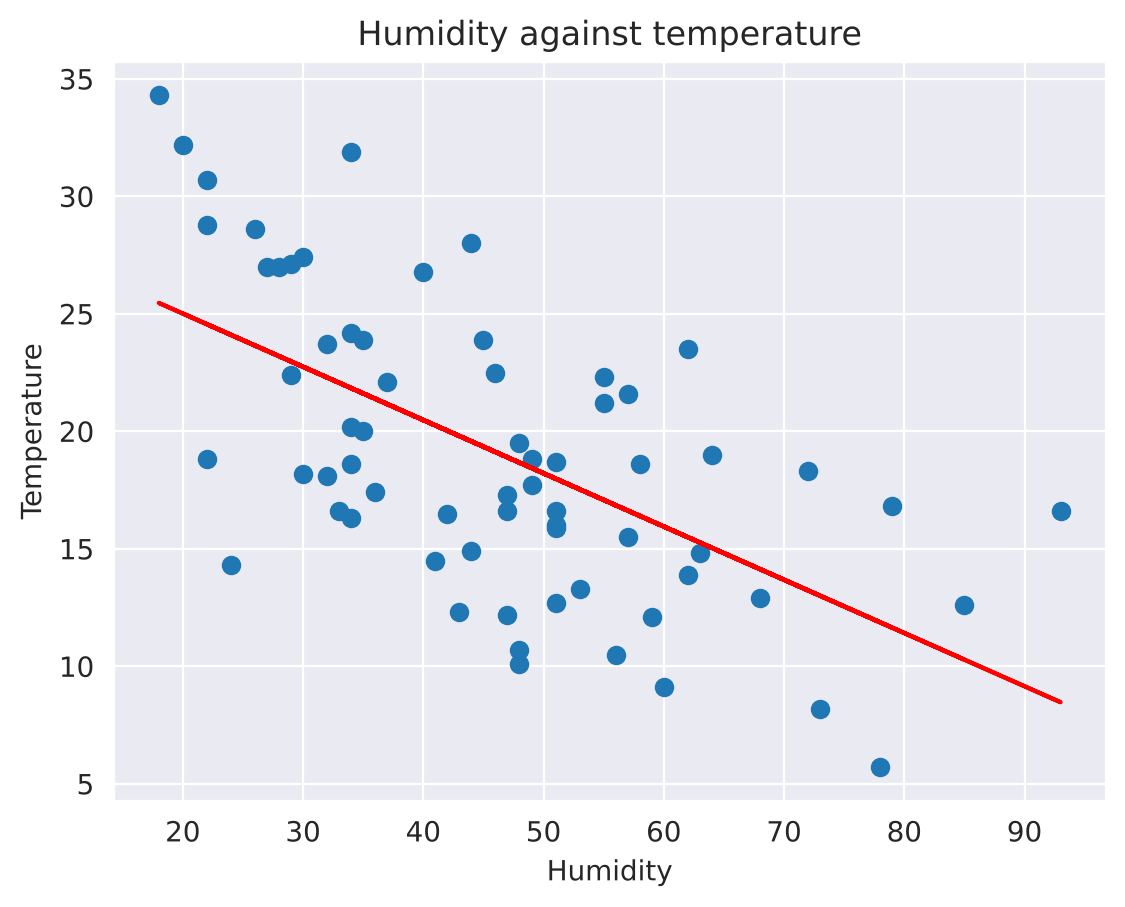

In [11]:
# Plot the prediction (the line) over the true value (the dots)
import seaborn as sns
sns.set_style("darkgrid")
plt.scatter(X_test, y_test)
plt.plot(X_test, predictions, 'r')
plt.title("Humidity against temperature")
plt.xlabel('Humidity')
plt.ylabel('Temperature')
plt.show()

We can measure the error of the model with metrics such as the **MAE (mean absolute error)**, the **MSE (mean squared error)** or the **R²** score. scikit-learn has a function for each of them, imported at the top of the notebook.

These functions take the `y_test` values and the `predictions` as arguments, and measure how far the predictions are from the true values. They are very helpful when looking for the best model.

In [12]:
# Compare the MAE the MSE and the R^2
mae = mean_absolute_error(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

print("MAE for the test set %.2f" % mae)
print("MSE for the test set %.2f" % mse)
print("R^2 for the test set %.2f" % r2)

MAE for the test set 4.27
MSE for the test set 24.44
R^2 for the test set 0.37


It is also interesting to compare these metrics on the `test set` and on the `train set`. A model that is much better on the train set than on the test set does not generalize well.

In [13]:
pred = model.predict(X_train)
mae = mean_absolute_error(y_train, pred)
mse = mean_squared_error(y_train, pred)
r2 = r2_score(y_train, pred)

print("MAE for the train set %.2f" % mae)
print("MSE for the train set %.2f" % mse)
print("R^2 for the train set %.2f" % r2)

MAE for the train set 4.77
MSE for the train set 31.08
R^2 for the train set 0.31


Remember: the higher the R², the better the fit. Here the test data gives a slightly higher R² than the training data. This may seem counterintuitive, but it can happen by chance with a particular split.
The R² computed on the test data is an unbiased measure of the prediction performance of the model.

## 6. Multivariate regression


We now apply the same method with several features: humidity, pressure, sunshine and cloud cover, to predict the temperature. We keep using the 3pm values for simplicity.

In [14]:
X = weather[['Humidity3pm', 'Cloud3pm', 'Pressure3pm', 'Sunshine']]
y = weather[['Temp3pm']]

### Split the data into a training set and a test set

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0, shuffle=True)

### Fit the model

In [16]:
# 1. Set up the model
model = LinearRegression()
# 2. Use fit
model.fit(X_train, y_train)
# 3. Check the score/accuracy
print("R^2 Score of the model: ", round(model.score(X_test, y_test), 3))
# 4. Print the coefficients of the linear model
print("Intercept: ", model.intercept_)
print("Features coefficients (weights): ", model.coef_)# Get the coefficients, w

R^2 Score of the model:  0.438
Intercept:  [361.96448369]
Features coefficients (weights):  [[-0.20850482  0.53595273 -0.33294024  0.39432442]]


### Prediction
We use the `predict()` function to predict the values of the test set from `X_test`.
The predictions can be compared to the true values, `y_test`.

In [17]:
print("Particular value of ['Humidity3pm', 'Cloud3pm', 'Pressure3pm', 'Sunshine']: ", X_test.iloc[0].values)
prediction = model.predict(X_test.iloc[[0]])
print("Prediction: ", prediction.flatten()[0], "but real value:" ,y_test.iloc[0].values.flatten()[0])

Particular value of ['Humidity3pm', 'Cloud3pm', 'Pressure3pm', 'Sunshine']:  [  28.     7.  1018.2    7.3]
Prediction:  23.75683012590224 but real value: 27.0


### Evaluation
Finally, we use the MAE (mean absolute error), the MSE (mean squared error) and the R² score to measure how far the predictions are from the true values.
These functions take the `y_test` values and the `predictions` as arguments.

In [18]:
# For the test data
predictions = model.predict(X_test)

print("MAE %.2f" % mean_absolute_error(y_test, predictions))
print("MSE %.2f" % mean_squared_error(y_test, predictions))
print("R^2 %.2f" % r2_score(y_test, predictions))

MAE 3.90
MSE 21.85
R^2 0.44


In [19]:
# For the training data
predictions = model.predict(X_train)

print("MAE %.2f" % mean_absolute_error(y_train, predictions))
print("MSE %.2f" % mean_squared_error(y_train, predictions))
print("R^2 %.2f" % r2_score(y_train, predictions))

MAE 4.13
MSE 24.11
R^2 0.47


#### Feature selection and error analysis in linear regression

Train error:  [11.02629934559219, 10.546349892010538, 7.945720705222089, 5.098494310131526]
Test error :  [10.906664493008066, 10.6643541285931, 7.555059569256484, 4.183558321749931]


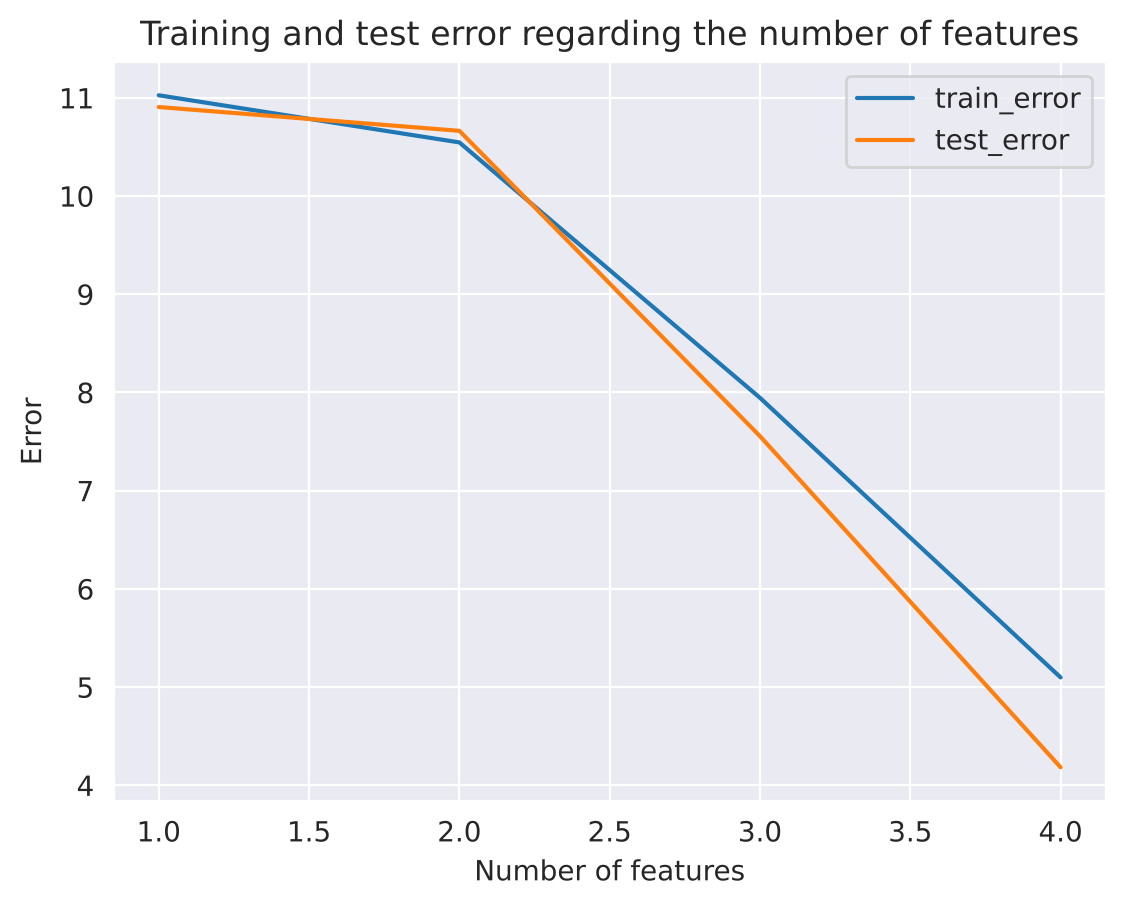

In [20]:
# Arrays to save the different errors
train_err = []
test_err = []

# Iterate over 1, 2, 3 and 4 features
for nbr_col in range(1, len(X.columns)+1):
    # Select the good number of features for X
    X_temp = X[X.columns[:nbr_col]]
    # Split the dat set
    X_train, X_test, y_train, y_test = train_test_split(X_temp, y, test_size=0.2, random_state=10)
    # Normalize the data
    # Create new scaler from MinMaxScaler()
    scaler = MinMaxScaler()
    # Fit and transform the original data
    scaler.fit(X_train, y_train)
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)
    # Create the linear model
    LR = LinearRegression(fit_intercept=False)
    # Fit the linear model
    LR.fit(X_train, y_train)

    # Compute and save the mean absolute error fro training and testing set
    train_err.append(mean_absolute_error(y_train, LR.predict(X_train)))
    test_err.append(mean_absolute_error(y_test, LR.predict(X_test)))

# Print the train and the test errors
print("Train error: ", train_err)
print("Test error : ", test_err)

plt.title("Training and test error regarding the number of features")
plt.plot(range(1,len(X.columns)+1), train_err, label="train_error")
plt.plot(range(1,len(X.columns)+1), test_err, label="test_error")
plt.legend(fontsize=10)
plt.xlabel("Number of features")
plt.ylabel("Error")
plt.show()
